# Appendix: Further Clustering Measures and k-Means Variants

Material that belongs to clustering but does not fit on the
[validation page](Clustering-Validation.ipynb) or on the two clustering pages. The first
sections are measures that the main page leaves out: the information-theoretic measure (NMI),
the gap statistic that turns the elbow into a decision, and the assignment problem behind the
maximum-matching score. The last two sections are the two variants of the algorithm itself
that the course uses but never derives: the k-means++ initialisation and the mini-batch
approximation. The page is reference material; the choices that have to be made in practice
are on the main pages.

---


### Adjusted Rand Index (ARI)

**Why Rand must be corrected.** Rand has no fixed zero point. If we keep the cluster sizes $n_1,\dots,n_r$ and the class sizes $m_1,\dots,m_k$ exactly as they are and simply shuffle the cluster labels among the points, agreement does not drop to zero: many pairs end up together, or apart, purely by coincidence. The average Rand over all such random labellings, written $\mathbb{E}[\text{Rand}]$, is (i) far from $0$ — already about $0.5$ for coarse balanced partitions — and (ii) a function of the group sizes only. So the *same* Rand value means different things in different problems, and any measure meant to be compared across problems must subtract this baseline.

**Where $\mathbb{E}[\text{Rand}]$ comes from.** Look at a single pair of points and two events:

- $A$: the pair is together in the (random) clustering. By symmetry of the shuffle, $P(A)=\dfrac{\sum_i \binom{n_i}{2}}{\binom{n}{2}}$, and this is the same for every pair.
- $B$: the pair is together in the true partition. The true labels are known and are never randomized, so $B$ is a *fixed property* of the pair; over all $\binom{n}{2}$ pairs it holds for the fraction $\dfrac{\sum_j \binom{m_j}{2}}{\binom{n}{2}}$ of them. Writing $P(B)$ is only a compact way of counting that fraction — the randomness lives entirely in the shuffling of the cluster labels, never in the truth.

Because the shuffle is blind to the classes, $A$ and $B$ are independent, so the expected number of pairs together in both partitions is

$$
\mathbb{E}[\text{TP}]
= \binom{n}{2}\,P(A)\,P(B)
= \frac{\left(\sum_i \binom{n_i}{2}\right)\left(\sum_j \binom{m_j}{2}\right)}{\binom{n}{2}}.
$$

Since the sizes are fixed, $\text{TP}+\text{FP}=\sum_i\binom{n_i}{2}$ and $\text{TP}+\text{FN}=\sum_j\binom{m_j}{2}$ hold in *every* labelling; hence $\text{FP}+\text{FN}=\sum_i\binom{n_i}{2}+\sum_j\binom{m_j}{2}-2\,\text{TP}$, and with $\text{Rand}=1-\frac{\text{FP}+\text{FN}}{\binom{n}{2}}$:

$$
\mathbb{E}[\text{Rand}]
= 1-\frac{\sum_i \binom{n_i}{2} + \sum_j \binom{m_j}{2} - 2\,\mathbb{E}[\text{TP}]}{\binom{n}{2}}.
$$

Everything on the right-hand side is a group size, so $\mathbb{E}[\text{Rand}]$ is **not a constant**: it is already large for a few large groups, and larger still when the clustering is very fine — exactly the over-segmentation inflation, because a labelling that puts no two points together collects every cross-class pair as "correctly split" without doing anything.

**The six points on [this page](Clustering-Validation.ipynb).** With $n_i=(2,3,1)$ and $m_j=(3,3)$: $\sum_i\binom{n_i}{2}=4$, $\sum_j\binom{m_j}{2}=6$, $\binom{6}{2}=15$, so $\mathbb{E}[\text{TP}]=\frac{4\cdot 6}{15}=1.6$ and

$$
\mathbb{E}[\text{Rand}] = 1-\frac{4+6-3.2}{15} \approx 0.547.
$$

| partition | Rand | $\mathbb{E}[\text{Rand}]$ | ARI |
|---|---|---|---|
| perfect, $(3,3)$ | $1.000$ | $0.520$ | $1.000$ |
| mixed, $(2,3,1)$ | $0.600$ | $0.547$ | $\approx 0.118$ |
| one cluster per point | $0.600$ | $0.600$ | $0.000$ |
| one big cluster | $0.400$ | $0.400$ | $0.000$ |

The two degenerate solutions sit *exactly* at their own chance levels, and the mixed clustering — which looks respectable at $0.600$ — clears chance by only $0.053$.

**The correction.** Since $\max(\text{Rand})=1$, attained exactly when the two partitions coincide up to relabelling,

$$
\text{ARI}
= \frac{\text{Rand} - \mathbb{E}[\text{Rand}]}{1 - \mathbb{E}[\text{Rand}]}.
$$

The numerator is the **excess over chance**; the denominator is the **largest possible excess**, so ARI rescales the improvement onto $[-1, 1]$. For the mixed clustering, $\text{ARI}=\frac{0.600-0.547}{1-0.547}=\frac{2}{17}\approx 0.118$ — only about 12% of the achievable improvement.

Interpretation:

* $\text{ARI}=1$ — the two partitions are identical (up to relabelling).
* $\text{ARI}=0$ — agreement equal to what blind shuffling with the **same cluster sizes and same class sizes** would produce. (Both degenerate rows of the table land exactly here.)
* $\text{ARI}<0$ — the partitions agree *less* than blind shuffling would; this happens when same-class points are systematically separated (or same-cluster points systematically land in different classes). With the mixed margins, the most adversarial arrangement scores $\text{Rand}=\frac{7}{15}\approx 0.467$ and $\text{ARI}=-\frac{3}{17}\approx -0.18$, so negative values are genuinely attainable.

**Practical properties.** The expectation uses only the margins of the contingency table — the permutation (hypergeometric) model, the same null that scikit-learn implements — and under this model the formulas above are exact, not approximations. ARI is invariant to relabelling, requires no relationship between $k$ and $r$, is bounded above by $1$, and is computed from the contingency table alone:

$$
\text{TP}=\sum_{ij}\binom{n_{ij}}{2},\quad
\text{FP}=\sum_i\binom{n_i}{2}-\text{TP},\quad
\text{FN}=\sum_j\binom{m_j}{2}-\text{TP},\quad
\text{TN}=\binom{n}{2}-\text{TP}-\text{FP}-\text{FN},
$$

so no pair ever has to be enumerated ($O(n+kr)$ instead of $O(n^2)$). Among pair-counting external measures it is the standard chance-corrected choice (the information-theoretic counterpart is AMI); in scikit-learn it is one call:

```python
adjusted_rand_score(true_labels, cluster_labels)
```


## Normalized Mutual Information (NMI)

Rand and ARI are built on pairs of points. An information-theoretic alternative asks how
much the cluster label tells us about the true class. Let $H(\mathbf{C})$ and
$H(\mathbf{T})$ be the entropies of the two partitions, estimated from the margins of the
contingency table, and $I(\mathbf{C};\mathbf{T})$ their mutual information:

$$
I(\mathbf{C};\mathbf{T})
= \sum_{i=1}^{r}\sum_{j=1}^{k} \frac{n_{ij}}{n}
  \log\frac{n\,n_{ij}}{n_i\,m_j},
\qquad
\mathrm{NMI} = \frac{I(\mathbf{C};\mathbf{T})}{\sqrt{H(\mathbf{C})\,H(\mathbf{T})}} \in [0,1]
$$

with the convention $0\log 0 = 0$. NMI equals $1$ exactly when the two partitions are
identical up to relabelling, and $0$ when the cluster labels carry no information about the
classes. It is well defined for $r \ne k$ and does not need a matching.

Its weakness is that it is **not corrected for chance**: with many small clusters, a random
labelling already gives a positive NMI, and the size of that baseline depends on $r$ and
$k$. Values are therefore not comparable across problems, which is why ARI (and the
adjusted mutual information, AMI) are preferred as defaults.

## Gap Statistic

Tibshirani, Walther and Hastie (2001) replace the visual elbow by a comparison with pure
noise. Generate $B$ reference datasets uniformly over the bounding box of the data, cluster
each of them into $k$ groups, and let

$$
W_k = \sum_{i=1}^{k} \frac{1}{2n_i}\sum_{\mathbf{x},\mathbf{x}'\in C_i}
      \|\mathbf{x} - \mathbf{x}'\|^2 ,
\qquad
\mathrm{Gap}(k) = \mathbb{E}^{*}\!\left[\log W_k\right] - \log W_k
$$

where $\mathbb{E}^{*}$ is the mean over the reference datasets. $W_k$ is the within-cluster
pairwise dispersion; by Lemma 2 of [k-Means](Clustering-Part2.ipynb) it is just the SSE
divided by $n_i$, so the gap compares the observed curve with the curve that structureless
data would produce. Choose the smallest $k$ such that

$$
\mathrm{Gap}(k) \;\ge\; \mathrm{Gap}(k+1) - s_{k+1},
\qquad
s_k = \mathrm{sd}^{*}\!\left[\log W_k\right]\sqrt{1 + 1/B},
$$

and $k = 1$ if no $k$ satisfies it. The extra cost is $B$ clusterings per candidate $k$,
which is why the rule is used less often than the silhouette.


## The Assignment Problem Behind Maximum Matching

Maximum matching with weights is an instance of the **assignment problem**: given the
$r \times k$ contingency table, choose a one-to-one pairing of rows and columns that
maximises the total weight. For square tables it is solved exactly by the Hungarian
algorithm, which is what `scipy.optimize.linear_sum_assignment` implements; for rectangular
tables the same routine returns an optimal pairing that leaves the surplus rows or columns
unmatched, which is exactly what we want when $r \ne k$.

The same problem appears whenever two sets must be paired under a one-to-one constraint:
students to schools, reviewers to papers, queries to documents, or features to components.
Zaki's chapter 17 develops it for clustering validation; the general treatment is in the
same book ({cite}`zaki2020data`).

### Maximum Weight Matching with `networkx`

The contingency table can also be read as a **bipartite graph**: clusters on one side,
classes on the other, and an edge of weight $n_{ij}$ whenever $n_{ij} > 0$. The maximum
matching score is then the weight of a maximum-weight matching of that graph.

`networkx.algorithms.matching.max_weight_matching` solves the general problem; it is not
restricted to bipartite graphs, so it may use an edge inside one partition if the graph has
one. Here every edge joins a cluster to a class, so the result is a matching of the bipartite
graph. Pass `weight="weight"` explicitly — with the default `weight=None` the edge weights
are ignored and the routine returns a maximum *cardinality* matching instead, which is what
an earlier version of this page did by mistake.

matched pairs and weights:
  C1 - setosa: 30
  virginica - C3: 50
  C2 - versicolor: 4

matched weight = 84   match score = 0.560


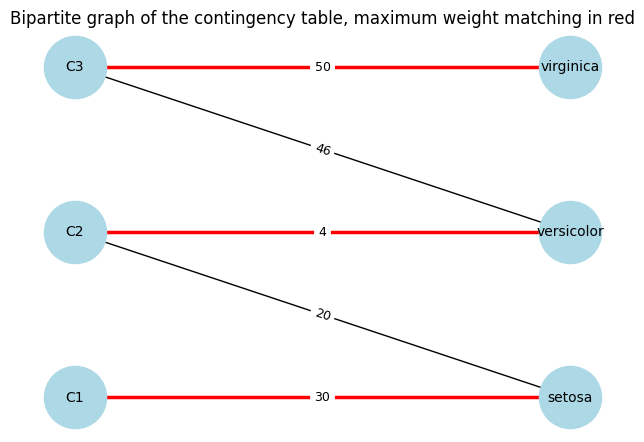

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

# the contingency table of the bad clustering, as a bipartite graph
table = np.array([[30, 0, 0], [20, 4, 0], [0, 46, 50]])
clusters = ["C1", "C2", "C3"]
classes = ["setosa", "versicolor", "virginica"]

G = nx.Graph()
G.add_nodes_from(clusters, bipartite=0)
G.add_nodes_from(classes, bipartite=1)
for i, cluster in enumerate(clusters):
    for j, cls in enumerate(classes):
        if table[i, j] > 0:
            G.add_edge(cluster, cls, weight=int(table[i, j]))

matching = nx.algorithms.matching.max_weight_matching(G, weight="weight")
total = sum(G[u][v]["weight"] for u, v in matching)

print("matched pairs and weights:")
for u, v in matching:
    print(f"  {u} - {v}: {G[u][v]['weight']}")
print(f"\nmatched weight = {total}   match score = {total / table.sum():.3f}")

pos = {**{n: (0, i) for i, n in enumerate(clusters)},
       **{n: (1, i) for i, n in enumerate(classes)}}
plt.figure(figsize=(6, 4))
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=2000, font_size=10)
nx.draw_networkx_edges(G, pos, edgelist=list(matching), width=2.5, edge_color="red")
nx.draw_networkx_edge_labels(G, pos, font_size=9,
                             edge_labels={(u, v): G[u][v]["weight"] for u, v in G.edges})
plt.title("Bipartite graph of the contingency table, maximum weight matching in red")
plt.show()

## k-Means++ Initialisation

Lloyd's algorithm converges to a local minimum, and which one it reaches depends on the
initial centroids. Two bad configurations are common: two centroids fall inside the same
natural cluster, which is then split in two, and a centroid falls in an empty region, from
which it captures points of several clusters.

**k-means++** (Arthur and Vassilvitskii, 2007) chooses the initial centroids one after
another, each of them far from those already chosen:

1. choose the first centroid uniformly at random from the data;
2. for every point $\mathbf{x}$ compute $D(\mathbf{x})$, the distance to the closest centroid
   chosen so far;
3. draw the next centroid from the data with probability

$$
p(\mathbf{x}) = \frac{D(\mathbf{x})^{2}}{\sum_{\mathbf{x}'} D(\mathbf{x}')^{2}} ;
$$

4. repeat until $k$ centroids are chosen, then run Lloyd's algorithm as usual.

A point that is already close to a chosen centroid has a small $D^2$ and is therefore
unlikely to be chosen again, so the initial centroids tend to fall in different clusters; a
group that has no centroid yet is far away from all of them, so its points carry most of the
mass of that distribution. The extra cost is one pass over the data per centroid, negligible
compared with the iterations of Lloyd's algorithm.

The guarantee behind the method is an *approximation* guarantee, not optimality: the expected
SSE of the partition returned after the first iteration is bounded by

$$
\mathbb{E}\left[\mathrm{SSE}\right] \;\le\; 8\left(\ln k + 2\right)\,\mathrm{SSE}_{\text{opt}} ,
$$

i.e. it is within a factor $O(\log k)$ of the optimal SSE. Local minima are therefore made
less likely, not impossible, which is why implementations repeat the whole procedure a few
times (`n_init` in scikit-learn, 10 by default) and keep the run with the smallest SSE. The
variant *greedy k-means++* (Bahmani et al., 2012) runs several candidate trials at each step
and keeps the one that lowers the potential most; it tightens the constant at the cost of a
larger setup.

The experiment below runs both initializations 100 times on the same data and compares the
distribution of the final SSE. A run is counted as *bad* if it ends more than 5% above the
best value ever found.


lowest SSE found in any run: 149.17

random      best =  149.17   median =  166.22   worst =  174.67   runs above 1.05 x best =  57%
k-means++   best =  149.17   median =  149.21   worst =  172.61   runs above 1.05 x best =  46%


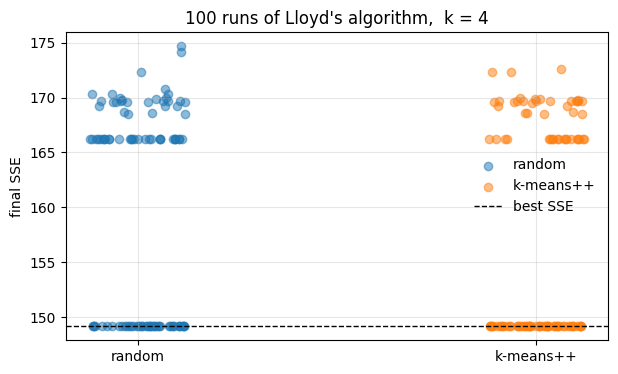

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# four blobs, one of them small and squeezed between two large ones: a geometry in which
# a bad initialization merges the small blob into a neighbour
X_hard, _ = make_blobs(n_samples=[100, 100, 100, 25],
                       centers=[[0.0, 0.0], [3.0, 0.0], [6.0, 0.0], [3.0, 1.2]],
                       cluster_std=[0.5, 0.5, 0.5, 0.4],
                       random_state=0)

runs = 100
results = {}
for init in ["random", "k-means++"]:
    results[init] = np.array([
        KMeans(n_clusters=4, init=init, n_init=1, random_state=s).fit(X_hard).inertia_
        for s in range(runs)])

best = min(v.min() for v in results.values())
print(f"lowest SSE found in any run: {best:.2f}\n")
for init, v in results.items():
    print(f"{init:10s}  best = {v.min():7.2f}   median = {np.median(v):7.2f}   "
          f"worst = {v.max():7.2f}   runs above 1.05 x best = {np.mean(v > 1.05 * best):4.0%}")

jitter = np.random.default_rng(0).uniform(-0.12, 0.12, runs)
plt.figure(figsize=(7, 4))
for (init, v), x0 in zip(results.items(), [0, 1]):
    plt.scatter(x0 + jitter, v, alpha=0.5, label=init)
plt.axhline(best, color="black", lw=1, ls="--", label="best SSE")
plt.xticks([0, 1], ["random", "k-means++"])
plt.ylabel("final SSE")
plt.title(f"{runs} runs of Lloyd's algorithm,  k = 4")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()


Read the two clouds as a statement about the initialization, not about the algorithm: once
initialized, both versions run exactly the same iterations. k-means++ lowers the *typical*
outcome — the median drops from 166.2 to 149.2, and the share of runs more than 5% above the
best value from 57% to 46% — but it does not remove local minima: its worst runs end in
essentially the same bad partitions as random initialization (172.6 against 174.7). That is
why the method is combined with a handful of restarts rather than trusted on its own. The
initialisation is also the point at which the algorithm can be made cheaper per iteration;
that is the subject of the next section.


## Mini-Batch k-Means

The per-iteration cost of Lloyd's algorithm is $O(nkd)$: both the assignment and the update
touch every point, so the whole dataset has to be in memory and every iteration pays for all
of it. For $n$ in the millions this dominates everything else, even though the information
gained per point per iteration is small. **Mini-batch k-means** (Sculley, 2010) replaces the
full pass by a random mini-batch of size $b \ll n$:

1. keep the current centroids $\boldsymbol{\mu}_1, \ldots, \boldsymbol{\mu}_k$;
2. draw a mini-batch $\mathcal{B}$ of $b$ points uniformly at random from the data;
3. for each $\mathbf{x} \in \mathcal{B}$ find its nearest centroid $c$, increment the counter
   $n_c$ of that centroid, and move it with the decaying learning rate
   $\eta = 1/n_c$:

$$
n_c \leftarrow n_c + 1,
\qquad
\boldsymbol{\mu}_c \leftarrow (1 - \eta)\,\boldsymbol{\mu}_c + \eta\,\mathbf{x} .
$$

Because $\eta = 1/n_c$, the centroid ends up as the running mean of the points that have been
assigned to it, which is the same fixed point as Lloyd's update, but only $b$ distances are
computed per iteration, so the cost is $O(bkd)$ and memory is $O(bd)$. Early points are
forgotten quickly (large $\eta$) and later ones barely move the centroid, which is what makes
the estimate stable without storing the data.

What is lost is exactness. The update is a stochastic approximation of Lloyd's step, so the
SSE fluctuates instead of decreasing monotonically, and with $b$ fixed the estimate of each
centroid keeps a sampling error, so the algorithm does not converge to a local minimum of the
full SSE. The trade is quantity for time: Sculley reports objectives within about $1\%$–$2\%$
of full k-means while being much faster on large datasets, and the gap shrinks as $b$ grows
and as the clusters are better separated. In scikit-learn the batch size is `batch_size`
(1024 by default); `MiniBatchKMeans` also keeps a per-centroid counter and reassigns a
centroid that has received too few points (`reassignment_ratio`), which stops a centre from
dying on an unlucky first batch.

The exact algorithm can also be accelerated without any approximation — a $k$-d tree or
triangle-inequality bounds skip most distance computations — but the asymptotic cost per
iteration stays $O(nkd)$.

The code below measures the trade on the same data at three sizes. The objective is nearly
the same and the time is not; the gap is small here because these blobs are well separated,
which is the easy case for the approximation.


       n  KMeans (s)   SSE full  mini (s)   SSE mini  SSE gap
   20000        0.04     198946      0.02     198991    0.02%
   80000        0.16     799412      0.02     799819    0.05%
  320000        0.65    3196655      0.04    3198041    0.04%


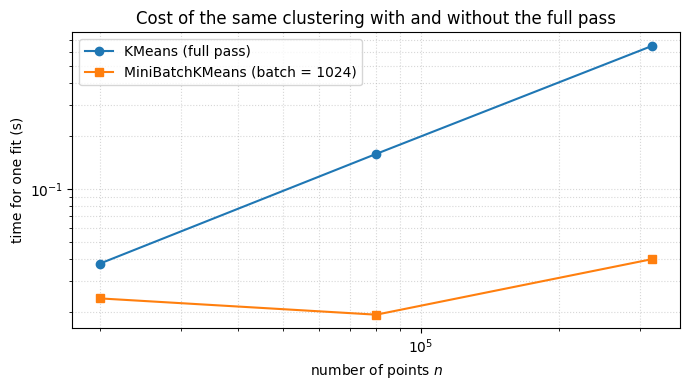

In [3]:
import time

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.datasets import make_blobs

sizes = [20_000, 80_000, 320_000]
X_all, _ = make_blobs(n_samples=max(sizes), n_features=10, centers=8, random_state=0)

rows = []
for n in sizes:
    X = X_all[:n]

    t0 = time.perf_counter()
    full = KMeans(n_clusters=8, init="k-means++", n_init=3, random_state=0).fit(X)
    t_full = time.perf_counter() - t0

    t0 = time.perf_counter()
    mini = MiniBatchKMeans(n_clusters=8, batch_size=1024, n_init=3, random_state=0).fit(X)
    t_mini = time.perf_counter() - t0

    rows.append((n, t_full, full.inertia_, t_mini, mini.inertia_))

print(f"{'n':>8} {'KMeans (s)':>11} {'SSE full':>10} {'mini (s)':>9} {'SSE mini':>10} {'SSE gap':>8}")
for n, t_full, sse_full, t_mini, sse_mini in rows:
    print(f"{n:>8} {t_full:>11.2f} {sse_full:>10.0f} {t_mini:>9.2f} {sse_mini:>10.0f}"
          f" {100 * (sse_mini - sse_full) / sse_full:>7.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, [r[1] for r in rows], "o-", label="KMeans (full pass)")
ax.plot(sizes, [r[3] for r in rows], "s-", label="MiniBatchKMeans (batch = 1024)")
ax.set(xscale="log", yscale="log",
       xlabel="number of points $n$", ylabel="time for one fit (s)")
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.legend()
ax.set_title("Cost of the same clustering with and without the full pass")
plt.tight_layout()
plt.show()
